# scRASCAL tutorial + hyper-parameter tuning

scRASCAL calls ecDNA from single-cell copy numbers. Instead of scoring all of a gene's cells at once (like scAmp), it first identifies multiple distributions of cells for a given gene using a Gaussian mixture model and evaluates whether those sub-distributions are ecDNA+ by the total mean and variance of the sub-distribution (**GMM**) or the mean and variance of each cell's
neighbourhood in the sub-distribution (**KNN**). This means that ecDNA that is present in only a small fraction of cells can still be found.

This method requires parameter tuning to optimize for rare sub-population identification. 

This tutorial shows how to interpret scRASCAL results. Sections 3-5 tune the GMM and section 6 tunes KNN, on a tumor from TCGA whose ecDNA is in a small fraction of its cells.

| Section | What it does |
|---|---|
| 1. Setup | paths, helper functions, figure style |
| 2. Example data | one tumor, two chromosomes |
| 3. Recommended GMM settings | optimized GMM settings, and what they call |
| 4. What the GMM sees | one gene's fitted distributions, scored one by one |
| 5. Tuning the GMM | change one setting at a time and compare |
| 6. Tuning KNN | the same for KNN |
| 7. Your own data | the same sweeps on your copy-number table |

Run the cells from top to bottom. Figures are saved in `notebooks/scRASCAL_tutorial_out/`.

## 1. Setup
Run this notebook from the `notebooks/` folder of the scamp repository, in a Python environment with scamp's
dependencies installed. All paths are relative to that folder, so nothing needs editing.

In [1]:
import os
import sys
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import ListedColormap
from scipy.stats import norm

# ---- paths: relative to scamp/notebooks/, where this notebook lives ----
SCAMP_CODE = Path("..")                                   # the scamp repository
MODEL = SCAMP_CODE / "pretrained_models" / "scamp_model_1.0"   # the scAmp model
DATA = SCAMP_CODE / "data"                                # the example data
OUT = Path("scRASCAL_tutorial_out")                       # this tutorial's runs and figures
OUT.mkdir(exist_ok=True)

# scamp's own functions: `pipelines.predict` calls each gene; the others redraw GMM fits and KNN neighbourhoods
sys.path.insert(0, str(SCAMP_CODE))
from scamp import models
from scamp.predict import pipelines
from scamp.predict import predict_methods as pm

SCAMP_MODEL = models.SCAMP.load(str(MODEL))

# ---- figure and table style ----
SURFACE, INK, INK2, GRID, BAR = "#fcfcfb", "#0b0b0b", "#52514e", "#e8e7e3", "#d9d8d4"
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # fixed colour order
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "savefig.dpi": 150,
    "font.size": 9, "text.color": INK, "axes.titlesize": 11, "axes.titlelocation": "left", "axes.titlecolor": INK,
    "axes.labelcolor": INK2, "axes.edgecolor": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelcolor": INK, "ytick.labelcolor": INK,
    "legend.frameon": False, "legend.fontsize": 8,
})


def show_table(df, caption=None, highlight=None, formats=None):
    """Displays a table without the index, with thousands separators and 2 decimals.

    highlight: optional True/False per row, e.g. the optimized settings, shown in bold on a light background.
    formats: optional {column: format string} for columns that need their own format.
    """
    sty = df.style.hide(axis="index").format(formats, precision=2, thousands=",")   # one call, so nothing is undone
    sty = sty.set_table_styles([
        {"selector": "caption", "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
        {"selector": "th", "props": "text-align: left; padding: 4px 10px; border-bottom: 1px solid #b8b7b2;"},
        {"selector": "td", "props": "text-align: left; padding: 3px 10px;"},
    ])
    if caption:
        sty = sty.set_caption(caption)
    if highlight is not None:
        bold = list(highlight)
        sty = sty.apply(lambda row: ["font-weight: bold; background-color: rgba(42, 120, 214, 0.12)"
                                     if bold[row.name] else "" for _ in row], axis=1)
    display(sty)

### Running scamp from the notebook
Each run calls `pipelines.predict`, the function `scamp predict` uses to call each gene, on a copy-number table
(one row per cell, one column per gene) and returns the gene table. The settings are `pipelines.predict`'s
arguments. `scamp predict` sets `filter_copy_number=2.5`, `trim_before_gmm=True` and `single_dist_scamp=True`
by default but `pipelines.predict` does not, so the settings below pass them, and the calls match the command
line. Genes are not grouped into ecDNA species here.

## 2. Example data
TCGA-AY-A54L-01A is a colorectal tumor profiled by scATAC-seq (1,950 cells). Whole-genome sequencing finds an
ecDNA on chromosome 13q12 (the CDK8, CDX2, FLT3 region), but scAmp identifies no ecDNA in this tumor. The
ecDNA is in a small fraction of the cells, which can only be picked up by scRASCAL.

The example file `data/TCGA-AY-A54L_chr13_20.tsv.gz` is in the scamp repository (compressed; the next cell
unpacks it once into `scRASCAL_tutorial_out/`, because scamp reads uncompressed `.tsv` files): copy numbers in 3 Mb
windows, one row per cell and one column per gene. To keep runs fast, it keeps every cell but only two
chromosomes, for their own reasons:

| Chromosome | In this tumor | Role |
|---|---|---|
| chr13 | carries the ecDNA (13q12) | the signal to find |
| chr20 | copy number gain, but ecDNA- | a control that should stay ecDNA− |

Each gene is scored on its own, so the subset gives the same call for each of its genes as the full table.

In [3]:
import gzip
import shutil

EXAMPLE = OUT / "TCGA-AY-A54L_chr13_20.tsv"   # unpacked from the compressed copy in scamp/data/
if not EXAMPLE.exists():
    with gzip.open(DATA / "TCGA-AY-A54L_chr13_20.tsv.gz", "rb") as packed, open(EXAMPLE, "wb") as unpacked:
        shutil.copyfileobj(packed, unpacked)
ROLE = {"chr13": "carries the ecDNA", "chr20": "gained, not ecDNA: control"}

# gene -> chromosome and start position (the copy-number tables write "-" in gene names as ".")
ann = (pd.read_csv(SCAMP_CODE / "reference" / "geneAnnohg38.tsv", sep="\t", usecols=["seqnames", "start", "symbol"])
       .assign(gene=lambda d: d["symbol"].astype(str).str.replace("-", ".", regex=False))
       .drop_duplicates("gene").set_index("gene"))
CHROM, START = ann["seqnames"], ann["start"]

cn = pd.read_csv(EXAMPLE, sep="\t", index_col=0)

gene_means = pd.DataFrame({"mean": cn.mean(), "Chromosome": CHROM.reindex(cn.columns)})
by_chrom = (gene_means.groupby("Chromosome")["mean"]
            .agg(**{"Genes": "size", "Median copy number": "median", "Genes scored (mean > 2.5)": lambda m: (m > 2.5).sum()})
            .reset_index())
by_chrom["Role"] = by_chrom["Chromosome"].map(ROLE)
show_table(by_chrom, caption=f"Example data: {cn.shape[0]:,} cells x {cn.shape[1]:,} genes")

Chromosome,Genes,Median copy number,Genes scored (mean > 2.5),Role
chr13,510,2.21,111,carries the ecDNA
chr20,670,2.96,529,"gained, not ecDNA: control"


## 3. Recommended GMM settings
These were identified as the optimal GMM settings, validated on 73 TCGA tumors comparing against whole-genome sequencing (AmpliconArchitect) and scAmp. Only genes on chromosome 13 are identified as ecDNA+, as expected. 

In [4]:
OPTIMIZED = {"predict_method": "GMM", "min_copy_number": 0.5,
             "max_percentile": 99.9, "one_thresh": 1.05, "min_weight": 0.05, "decision_rule": 0.6,
             "n_draws": 100,
             # `scamp predict`'s defaults, which pipelines.predict does not set
             "filter_copy_number": 2.5, "trim_before_gmm": True, "single_dist_scamp": True}
# every other setting is left at its default

base, _ = pipelines.predict(cn, [], str(MODEL), None, **OPTIMIZED)
positive = base[base["prediction"]]
show_table(
    positive.assign(Chromosome=positive["gene"].map(CHROM))
            [["gene", "Chromosome", "mean", "Probability", "Weight"]]
            .rename(columns={"gene": "Gene", "mean": "Mean copy number", "Probability": "Score",
                             "Weight": "Share of cells in the ecDNA+ distribution"}),
    caption=f"{len(positive)} of {len(base):,} scored genes are ecDNA+ with optimized settings",
    formats={"Share of cells in the ecDNA+ distribution": "{:.0%}"},
)

scamp predict scRASCAL_tutorial_out/gmm_optimized scRASCAL_tutorial_out/TCGA-AY-A54L_chr13_20.tsv ../pretrained_models/scamp_model_1.0 --cNMF-log-dir scRASCAL_tutorial_out/gmm_optimized/cnmf_tmp --predict-method=GMM --deconvolution-method=auto --min-copy-number=0.5 --max-percentile=99.9 --one-thresh=1.05 --min-weight=0.05 --decision-rule=0.6 --n-draws=100 --seed=10
  (already run with these settings: loading the saved output)


Gene,Chromosome,Mean copy number,Score,Share of cells in the ecDNA+ distribution
USP12.AS1,chr13,5.02,0.70,14%
USP12.AS2,chr13,5.02,0.70,14%
LINC00412,chr13,5.02,0.70,14%
RPL21,chr13,5.02,0.70,14%
SNORD102,chr13,5.02,0.70,14%
SNORA27,chr13,5.02,0.70,14%
RASL11A,chr13,5.02,0.70,14%
GTF3A,chr13,5.02,0.70,14%
MTIF3,chr13,5.02,0.70,14%
LNX2,chr13,5.02,0.70,14%


## 4. What the GMM sees
For each gene, the GMM splits the cells into distributions. If more than one distribution holds more than
`min_weight` of the cells, each one is scored separately: 1,000 cells are drawn from it (`n_draws` times),
scored by the scAmp model, and averaged. The gene is ecDNA+ if any distribution scores at least `decision_rule`.

`plot_gmm` redraws this for one gene. The grey histogram is the gene's cells after trimming, and each line is one
fitted distribution: **solid = ecDNA+, dashed = ecDNA−, dotted = ignored** (too few cells).

In [5]:
def score_distributions(gene, gmm, min_weight=0.05, var_scale=0.5, n_draws=100, decision_rule=0.6):
    """Scores each fitted distribution the way scamp does. Returns {distribution index: score, or None if ignored}.

    Several distributions above min_weight: each is scored on n_draws x 1,000 cells drawn from it (same seeds as
    scamp, variance x weight**var_scale, no filtering), averaged. Only one above min_weight: the gene's untrimmed
    cells are scored with published scAmp settings (2 / 99.9 / 2.5), as scamp does by default.
    """
    raw = cn[gene].to_numpy(float).reshape(-1, 1)
    above = gmm.weights_ > min_weight
    if above.sum() == 1:
        _, score = pm.SCAMP_ecDNA_predict(SCAMP_MODEL, raw, [], np.array([gene]), decision_rule, False,
                                          min_copy_number=2.0, max_percentile=99.9, filter_copy_number=2.5)
        return {i: (float(score) if above[i] else None) for i in range(gmm.n_components)}

    seed = pm._vector_seed(raw)
    scores = {}
    for i in range(gmm.n_components):
        if not above[i]:
            scores[i] = None
            continue
        mean, var, weight = gmm.means_[i, 0], gmm.covariances_[i, 0, 0], gmm.weights_[i]
        sd = np.sqrt(var * weight**var_scale)
        # all draws at once: one column of 1,000 cells per draw, summarized and scored in a single model call
        draws = np.column_stack([np.random.default_rng([seed, i] if k == 0 else [seed, i, k]).normal(mean, sd, 1000)
                                 for k in range(n_draws)])
        X, _ = SCAMP_MODEL.prepare_copy_numbers(draws, np.array([gene] * n_draws), min_copy_number=-np.inf,
                                                max_percentile=100, filter_copy_number=-np.inf)
        scores[i] = float(SCAMP_MODEL.proba(X)[:, 1].mean())
    return scores


def plot_gmm(gene, preds=None, min_copy_number=0.5, max_percentile=99.9, one_thresh=1.05, kneedle_coeff=3,
             min_weight=0.05, var_scale=0.5, n_draws=100, decision_rule=0.6, ax=None):
    """One gene's trimmed cells (histogram) with its fitted distributions, each styled by its call.

    Refits the GMM exactly as scamp does (same trimming, same fit, fixed random state). preds: a run's gene table,
    to show scamp's own call in the title. Returns the fitted GMM and the score of each distribution.
    """
    cells = pm._trim_cells(cn[gene].to_numpy(float), max_percentile, min_copy_number)
    gmm = pm._GMM_fit(cells.reshape(-1, 1), None, one_thresh, 15, kneedle_coeff)
    scores = score_distributions(gene, gmm, min_weight, var_scale, n_draws, decision_rule)

    ax = ax or plt.subplots(figsize=(6, 3.6))[1]
    counts, _, _ = ax.hist(cells, bins=60, density=True, color=BAR, edgecolor="none")
    grid = np.linspace(cells.min(), cells.max(), 1000)
    for colour, i in zip(SLOTS, np.argsort(gmm.means_[:, 0])):      # colours in order of mean copy number
        mean, var, weight, score = gmm.means_[i, 0], gmm.covariances_[i, 0, 0], gmm.weights_[i], scores[i]
        if score is None:
            style, status = ":", "ignored (weight <= min_weight)"
        elif score >= decision_rule:
            style, status = "-", f"ecDNA+ (score {score:.2f})"
        else:
            style, status = "--", f"ecDNA- (score {score:.2f})"
        ax.plot(grid, weight * norm.pdf(grid, mean, np.sqrt(var)), color=colour, lw=2, ls=style,
                label=f"{weight:.0%} of cells, mean {mean:.1f}: {status}")

    title = f"{gene} ({CHROM.get(gene, '?')})"
    if preds is not None and gene in set(preds["gene"]):   # scamp's own call for this gene
        row = preds.set_index("gene").loc[gene]
        title += f": {'ecDNA+' if row['prediction'] else 'ecDNA-'}, score {float(row['Probability']):.2f}"
    elif preds is not None:
        title += ": not scored (mean copy number below 2.5)"
    ax.set(title=title, xlabel="copy number", ylabel="density", ylim=(0, 1.35 * counts.max()))
    ax.legend(loc="upper right")
    return gmm, scores

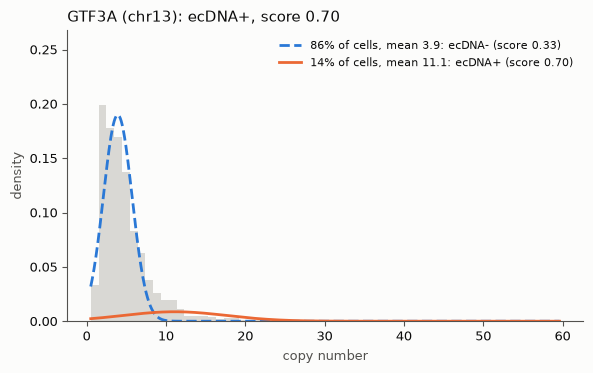

12 genes share GTF3A's copy numbers (and its call): USP12.AS1, USP12.AS2, LINC00412, RPL21, SNORD102, SNORA27, RASL11A, GTF3A, MTIF3, LNX2, POLR1D, GSX1


In [6]:
GENE = "GTF3A"   # in the ecDNA+ block
fig, ax = plt.subplots(figsize=(6, 3.8))
plot_gmm(GENE, base, ax=ax)
fig.tight_layout()
fig.savefig(OUT / "gmm_fits_example.png")
plt.show()

# genes with exactly the same copy numbers (same 3 Mb window): same fit, same call
same_window = sorted(cn.columns[cn.eq(cn[GENE], axis=0).all()], key=lambda gene: START.get(gene, 0))
print(f"{len(same_window)} genes share {GENE}'s copy numbers (and its call):", ", ".join(same_window))


## 5. Tuning the GMM
The GMM calls a gene from its distributions of cells:

1. **Trim** the gene's cells (`min_copy_number`, `max_percentile`). Genes whose mean copy number is below 2.5
   (`filter_copy_number`) are not called.
2. **Fit the GMM** to identify the number of distributions that exist (`one_thresh`: how readily it settles on a
   single distribution).
   If only one distribution holds more than `min_weight` of the cells, the gene is scored as scAmp would score it
   instead.
3. **Ignore** small distributions: those holding `min_weight` of the cells or less are not scored.
4. **Score** each remaining distribution: draw 1,000 cells from it, score them with the scAmp model, and average over `n_draws` draws.
5. The gene is **ecDNA+ if any distribution scores at least `decision_rule`**.

Below, each run changes **one** of the optimized settings and keeps the rest. For reference,
the 8 genes that whole-genome sequencing (AmpliconArchitect) places on this tumor's ecDNA are marked \*.


In [7]:
# Whole-genome sequencing (AmpliconArchitect): one ecDNA in this tumor, 8 genes on 13q12 (copy number ~6.8).
# Source: TCGA AmpliconArchitect gene list for TCGA-AY-A54L-01A.
WGS_ECDNA = ["CDX2", "FLT3", "GSX1", "LNX2", "PDX1", "PLUT", "POLR1D", "URAD"]
scored = set(base["gene"])
print(f"WGS ecDNA genes scored in the example data (mean > 2.5): {sum(g in scored for g in WGS_ECDNA)} of 8")
print("not scored:", [g for g in WGS_ECDNA if g not in scored] or "none")

WGS ecDNA genes scored in the example data (mean > 2.5): 8 of 8
not scored: none


### The sweep
The settings are grouped by what they control. The values are chosen to span a realistic range that influences the calls, so the table and chart below show where the result changes. Each value is one `pipelines.predict` run (24 in total,
5 at a time, about 5 minutes).

In [8]:
SWEEP = {   # setting -> values to try; each list includes the optimized value
    # how each distribution is scored and called
    "decision_rule": [0.3, 0.4, 0.5, 0.6, 0.71],     # gene scores here: 0.70, 0.54, 0.49, 0.44, 0.33, <= 0.29
    "n_draws": [1, 2, 100],                           # from 2 draws on, the calls are stable here
    # which distributions count
    "min_weight": [0.05, 0.14, 0.145],                # the rare distribution holds 14.2% of the cells
    # how many distributions the GMM finds
    "one_thresh": [1.0, 1.05, 1.15, 1.2],
    # which cells the GMM is fitted on
    "min_copy_number": [-1, 0.5, 2, 3, 5],
    "max_percentile": [99.5, 99.9, 99.95, 100],
}


def run_sweep(optimized, sweep, counts_df=cn, workers=5):
    """Calls the genes in counts_df once per (setting, value): the optimized settings with that one setting changed.

    Returns one row per (run, gene) with the call; values are kept as text ("1", "0.05", ...) so they print as
    written in `sweep`.
    """
    runs = [(setting, value, {**optimized, setting: value}) for setting, values in sweep.items() for value in values]
    print(f"{len(runs)} runs of pipelines.predict: the optimized settings, one changed")
    with ThreadPoolExecutor(max_workers=workers) as pool:   # `workers` runs at a time
        results = list(pool.map(lambda r: pipelines.predict(counts_df, [], str(MODEL), None, **r[2])[0], runs))
    calls = pd.concat([preds[["gene", "prediction"]].assign(setting=setting, value=str(value))
                       for (setting, value, _), preds in zip(runs, results)], ignore_index=True)
    calls["chrom"] = calls["gene"].map(CHROM)
    print("done")
    return calls


calls = run_sweep(OPTIMIZED, SWEEP)


24 runs of: scamp predict OUT/<run name> TCGA-AY-A54L_chr13_20.tsv <model> <optimized settings, one changed>
done


### Results
For each run: how many genes it calls ecDNA+, on chr13 (the ecDNA) and on chr20 (not ecDNA).
The optimized settings are highlighted.


In [9]:
def sweep_table(calls, optimized, caption, chroms=("chr13", "chr20")):
    """One row per run: the number of genes called ecDNA+, in total and on each of `chroms`; optimized rows highlighted."""
    runs = pd.MultiIndex.from_frame(calls[["setting", "value"]].drop_duplicates())
    positive = calls[calls["prediction"]]
    count = lambda rows: rows.groupby(["setting", "value"]).size().reindex(runs, fill_value=0)
    table = pd.DataFrame({"Genes called ecDNA+": count(positive),
                          **{f"on {c}": count(positive[positive["chrom"] == c]) for c in chroms}}).reset_index()
    is_optimized = [str(optimized[s]) == v for s, v in zip(table["setting"], table["value"])]
    table["setting"] = [s if first else "" for s, first in zip(table["setting"], ~table["setting"].duplicated())]
    show_table(table.rename(columns={"setting": "Setting", "value": "Value"}), caption=caption, highlight=is_optimized)


WGS_SET = set(WGS_ECDNA)
sweep_table(calls, OPTIMIZED, "GMM sweep: one setting changed at a time from the optimized settings")


Setting,Value,Genes called ecDNA+,on chr13,on chr20
--decision-rule,0.3,28,28,0
,0.4,24,24,0
,0.5,16,16,0
,0.6,12,12,0
,0.71,0,0,0
--n-draws,1,16,16,0
,2,12,12,0
,100,12,12,0
--min-weight,0.05,12,12,0
,0.14,12,12,0


The figure below shows the chr13 genes that were ecDNA+ with any of the settings on the y-axis, and the settings on the x-axis.

- **Red** = called ecDNA+, light grey = ecDNA-.
- \* = gene in the ecDNA found by whole-genome sequencing (AmpliconArchitect), shown for reference

The optimized value for each setting is in **bold**, with its column outlined.

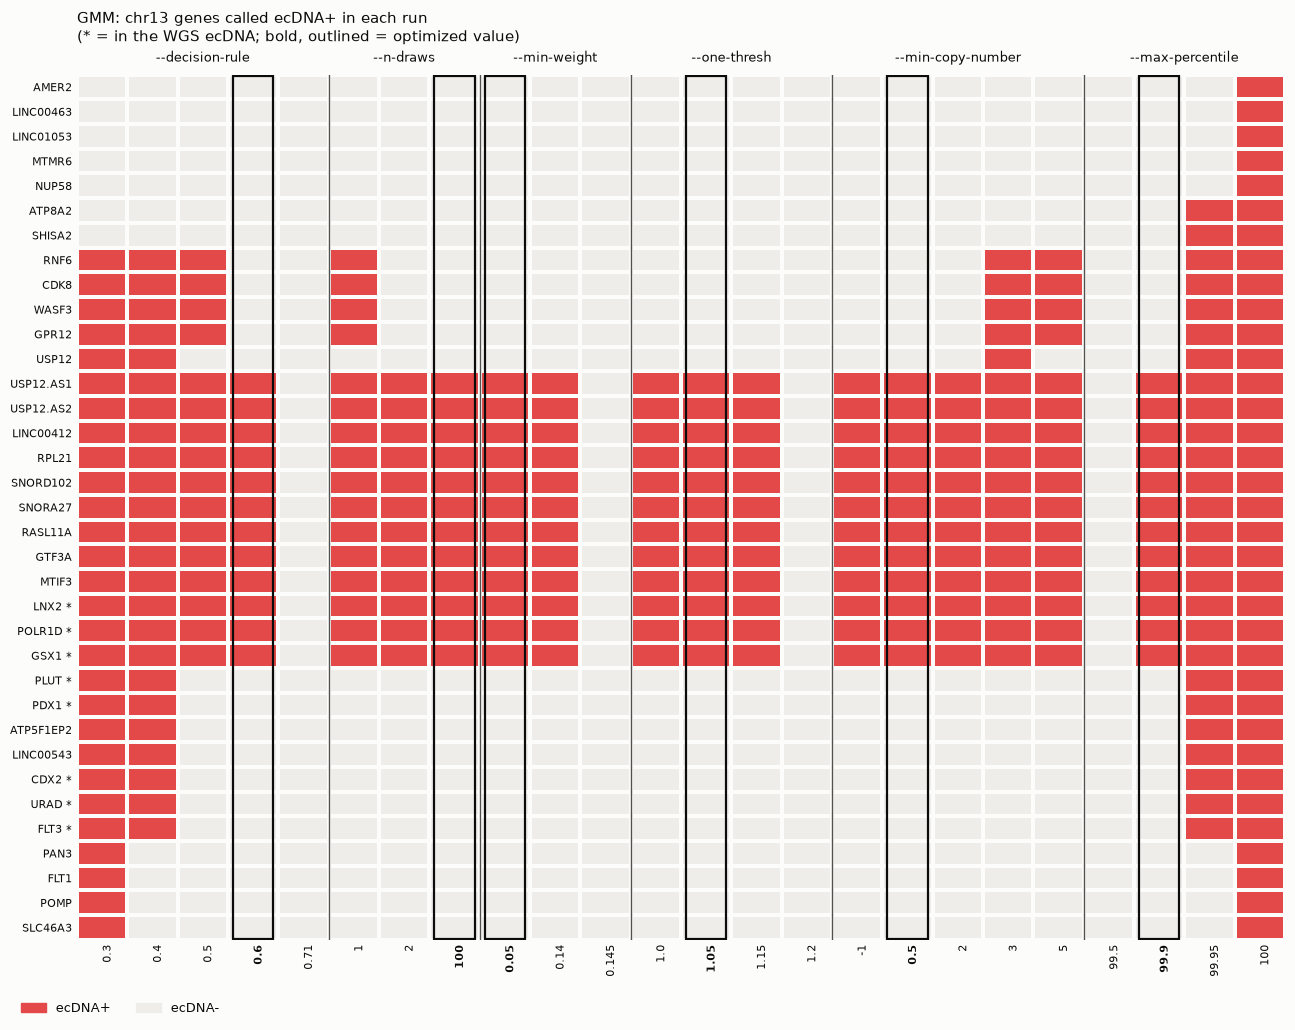

In [10]:
from matplotlib.patches import Patch, Rectangle


def plot_sweep_genes(calls, sweep, optimized, title, filename, chrom="chr13", reference=None,
                     reference_label="in the WGS ecDNA", max_rows=60):
    """Which genes each run calls ecDNA+ (red) or not (grey); one column per run.

    Rows: genes on `chrom` (None = all chromosomes) called ecDNA+ in any run, plus the `reference` genes (*), in
    genome order; at most `max_rows`, keeping the reference genes and the genes called in the most runs.
    The optimized value of each setting: bold label, outlined column.
    """
    reference = WGS_SET if reference is None else set(reference)
    hits = calls[calls["prediction"] & ((calls["chrom"] == chrom) if chrom else True)]
    ranked = list(reference & set(calls["gene"])) + list(hits["gene"].value_counts().index)
    region = list(dict.fromkeys(ranked))[:max_rows]
    if not region:
        print("no gene is called ecDNA+ in any run")
        return
    chrom_order = lambda c: int(c[3:]) if str(c)[3:].isdigit() else 99
    region.sort(key=lambda gene: (chrom_order(CHROM.get(gene, "")), START.get(gene, 0)))
    columns = [(setting, str(value)) for setting, values in sweep.items() for value in values]
    called = (calls[calls["gene"].isin(region)]
              .pivot_table(index="gene", columns=["setting", "value"], values="prediction", aggfunc="first")
              .reindex(index=region, columns=columns).fillna(False).to_numpy(int))   # 1 = ecDNA+, 0 = ecDNA-
    pale, red = "#eeedea", SLOTS[7]

    fig, ax = plt.subplots(figsize=(max(6, 0.48 * len(columns) + 1.5), 0.22 * len(region) + 2.6))
    ax.pcolormesh(called, cmap=ListedColormap([pale, red]), vmin=0, vmax=1, edgecolors=SURFACE, linewidth=1.5)
    ax.set_ylim(len(region), 0)
    labels = [g + ("" if chrom else f" ({CHROM.get(g, '?')})") + (" *" if g in reference else "") for g in region]
    ax.set_yticks(np.arange(len(region)) + 0.5, labels, fontsize=8)
    ax.set_xticks(np.arange(len(columns)) + 0.5, [v for _, v in columns], rotation=90, ha="right",
                  va="top", rotation_mode="anchor", fontsize=8)
    for x, (tick, (s, v)) in enumerate(zip(ax.get_xticklabels(), columns)):
        if str(optimized[s]) == v:
            tick.set_fontweight("bold")
            ax.add_patch(Rectangle((x + 0.1, 0.05), 0.8, len(region) - 0.1, fill=False, edgecolor=INK, lw=1.6))
    start = 0
    for setting, values in sweep.items():   # setting name above each group of columns, a line between groups
        ax.text(start + len(values) / 2, -0.4, setting, ha="center", va="bottom", fontsize=9)
        if start:
            ax.axvline(start, color=INK2, lw=1)
        start += len(values)
    ax.tick_params(length=0)
    ax.spines[["left", "bottom"]].set_visible(False)
    fig.legend(handles=[Patch(color=red, label="ecDNA+"), Patch(color=pale, label="ecDNA-")],
               loc="lower left", bbox_to_anchor=(0.01, 0.0), ncol=2, fontsize=9)
    ax.set_title(f"{title}\n(* = {reference_label}; bold, outlined = optimized value)", pad=24)
    fig.tight_layout(rect=(0, 0.035, 1, 1))
    fig.savefig(OUT / filename)


plot_sweep_genes(calls, SWEEP, OPTIMIZED, "GMM: chr13 genes called ecDNA+ in each run", "gmm_sweep_genes.png")


## 6. Tuning KNN
KNN starts like the GMM (trim the cells, fit the distributions) but then calls the gene from single cells:

1. **Trim** the gene's cells (`min_copy_number`, `max_percentile`) and **fit the GMM** (`one_thresh`). If only one distribution holds more than `min_weight` of the cells, the gene is scored
   as scAmp would score it instead.
2. **Assign** each cell to a distribution.
3. Sort the cells by copy number. Each cell's **neighbourhood** is its 100 nearest cells in the same
   distribution, shifted so its mean is the distribution's mean.
4. **Score** each neighbourhood with the scAmp model, if its variance is above `knn_min_var` (and its mean
   above 2.5). A neighbourhood scoring at least `decision_rule` is ecDNA+.
5. The gene is **ecDNA+ if more than 0.1% of its cells** have an ecDNA+ neighbourhood.

The other KNN options (`k`, `knn_min_mean`, `var_scale`, `kneedle_coeff`) are left at the code's defaults.

The GMM asks *is a whole distribution ecDNA-like?* KNN asks *are a few cells in ecDNA-like neighbourhoods?*


In [11]:
OPTIMIZED_KNN = {"predict_method": "KNN", "min_copy_number": 0.5,
                 "max_percentile": 100, "one_thresh": 1.05, "min_weight": 0.05, "decision_rule": 0.6,
                 "knn_min_var": float("-inf"),
                 # `scamp predict`'s defaults, which pipelines.predict does not set
                 "filter_copy_number": 2.5, "trim_before_gmm": True, "single_dist_scamp": True}
# every other setting is left at its default

base_knn, _ = pipelines.predict(cn, [], str(MODEL), None, **OPTIMIZED_KNN)
positive_knn = base_knn[base_knn["prediction"]]
show_table(
    positive_knn.assign(Chromosome=positive_knn["gene"].map(CHROM))
                [["gene", "Chromosome", "mean", "NumberOfPositiveCells"]]
                .rename(columns={"gene": "Gene", "mean": "Mean copy number",
                                 "NumberOfPositiveCells": "Cells with an ecDNA+ neighbourhood"}),
    caption=f"{len(positive_knn)} of {len(base_knn):,} scored genes are ecDNA+ with KNN (optimized settings)",
)


scamp predict scRASCAL_tutorial_out/knn_optimized scRASCAL_tutorial_out/TCGA-AY-A54L_chr13_20.tsv ../pretrained_models/scamp_model_1.0 --cNMF-log-dir scRASCAL_tutorial_out/knn_optimized/cnmf_tmp --predict-method=KNN --deconvolution-method=auto --min-copy-number=0.5 --max-percentile=100 --one-thresh=1.05 --min-weight=0.05 --decision-rule=0.6 --knn-min-var=-inf --seed=10
  (already run with these settings: loading the saved output)


Gene,Chromosome,Mean copy number,Cells with an ecDNA+ neighbourhood
AMER2,chr13,3.04,2
LINC00463,chr13,3.04,2
LINC01053,chr13,3.04,2
MTMR6,chr13,3.04,2
NUP58,chr13,3.04,2
ATP8A2,chr13,3.65,3
SHISA2,chr13,3.65,3
RNF6,chr13,4.20,5
CDK8,chr13,4.20,5
WASF3,chr13,4.20,5


### What KNN sees
`plot_knn` redoes KNN for one gene, drawn as for the GMM: the gene's cells after trimming (grey histogram) and the
distributions KNN fits. **Solid** = the distribution holds cells with an ecDNA+ neighbourhood, **dashed** = it holds
none; red triangles mark those cells' copy numbers. With about 1,950 cells, more than 1.9 such cells (0.1%) make
the gene ecDNA+.


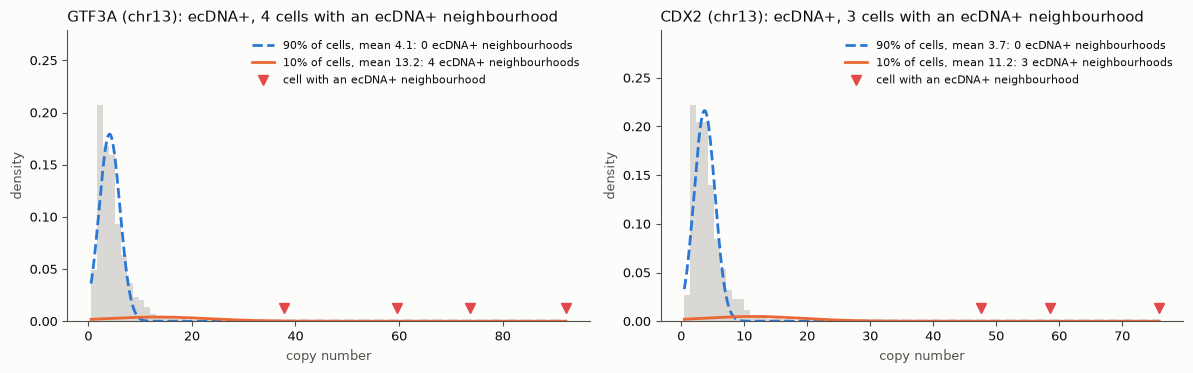

In [12]:
def knn_cells(gene, min_copy_number=0.5, max_percentile=100, one_thresh=1.05, kneedle_coeff=3, min_weight=0.05,
              var_scale=0.5, k=100, decision_rule=0.6, knn_min_mean=2.5, knn_min_var=-np.inf):
    """Calls each cell's neighbourhood the way scamp's KNN does. Defaults: the optimized KNN settings.

    Returns a dict with the sorted cells, each cell's distribution, ecDNA+ neighbourhood (True/False)
    and the GMM; or None if the gene is not called by KNN (too few cells after
    trimming, or one distribution: scored as scAmp would).
    """
    raw = cn[gene]
    cells = pm._trim_cells(raw.to_numpy(float), max_percentile, min_copy_number, 2.5)
    if cells is None or len(cells) < 15:
        return None
    gmm = pm._GMM_fit(cells.reshape(-1, 1), None, one_thresh, 15, kneedle_coeff)   # fitted on all trimmed cells
    if len(cells) > 4000:   # scamp subsamples large inputs, seeded from the gene's copy numbers
        cells = np.random.default_rng(pm._vector_seed(raw)).choice(cells, 4000, replace=False)
    cells = np.sort(cells)
    if (gmm.weights_ > min_weight).sum() == 1:
        return None

    # each cell joins its most likely distribution, with variances narrowed by weight**var_scale
    sd = np.sqrt(gmm.covariances_.ravel() * gmm.weights_**var_scale)
    labels = np.argmax(np.log(gmm.weights_)[:, None]
                       + norm.logpdf(cells[None, :], gmm.means_.ravel()[:, None], sd[:, None]), axis=0)
    label_mean = {label: cells[labels == label].mean() for label in np.unique(labels)}

    n = len(cells)
    positive = np.zeros(n, bool)
    for i in range(n):   # grow the neighbourhood one nearest cell at a time, within the same distribution
        left, right, size = i - 1, i + 1, 1
        while size < k + 1:
            left_ok = left >= 0 and labels[left] == labels[i]
            right_ok = right < n and labels[right] == labels[i]
            if not (left_ok or right_ok):
                break
            if left_ok and (not right_ok or cells[i] - cells[left] <= cells[right] - cells[i]):
                left -= 1
            else:
                right += 1
            size += 1
        hood = cells[left + 1:right]
        hood = hood - (hood.mean() - label_mean[labels[i]])   # shifted to the distribution's mean
        if hood.mean() > knn_min_mean and hood.var() > knn_min_var:
            _, score = pm.SCAMP_ecDNA_predict(SCAMP_MODEL, hood.tolist(), [], np.array([gene]), decision_rule, False,
                                              min_copy_number=-np.inf, max_percentile=100, filter_copy_number=-np.inf)
            positive[i] = score >= decision_rule
    return {"cells": cells, "labels": labels, "positive": positive, "gmm": gmm}


def plot_knn(gene, preds=None, ax=None, **settings):
    """One gene's trimmed cells (histogram) with the distributions KNN fits; solid = holds cells with an ecDNA+
    neighbourhood, dashed = none. Red triangles: the copy numbers of those cells. preds: a KNN run's gene table,
    to show scamp's own call in the title. Returns knn_cells' result.
    """
    ax = ax or plt.subplots(figsize=(6, 3.8))[1]
    result = knn_cells(gene, **settings)
    if result is None:
        ax.set_title(f"{gene}: not scored by KNN neighbourhoods")
        return None
    cells, labels, positive, gmm = result["cells"], result["labels"], result["positive"], result["gmm"]

    counts, _, _ = ax.hist(cells, bins=80, density=True, color=BAR, edgecolor="none")
    grid = np.linspace(cells.min(), cells.max(), 2000)
    for colour, i in zip(SLOTS, np.argsort(gmm.means_[:, 0])):   # colours in order of mean copy number
        n_pos = int(positive[labels == i].sum())
        mean, var, weight = gmm.means_[i, 0], gmm.covariances_[i, 0, 0], gmm.weights_[i]
        ax.plot(grid, weight * norm.pdf(grid, mean, np.sqrt(var)), color=colour, lw=2, ls="-" if n_pos else "--",
                label=f"{weight:.0%} of cells, mean {mean:.1f}: {n_pos} ecDNA+ neighbourhoods")
    ax.plot(cells[positive], np.full(positive.sum(), 0.06 * counts.max()), "v", color=SLOTS[7], ms=7,
            label="cell with an ecDNA+ neighbourhood")
    title = f"{gene} ({CHROM.get(gene, '?')})"
    if preds is not None and gene in set(preds["gene"]):   # scamp's own call for this gene
        row = preds.set_index("gene").loc[gene]
        title += f": {'ecDNA+' if row['prediction'] else 'ecDNA-'}, {row['NumberOfPositiveCells']} cells with an ecDNA+ neighbourhood"
    ax.set(title=title, xlabel="copy number", ylabel="density", ylim=(0, 1.35 * counts.max()))
    ax.legend(loc="upper right")
    return result


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_knn("GTF3A", base_knn, ax=axes[0])
plot_knn("CDX2", base_knn, ax=axes[1])   # ecDNA- with the GMM, ecDNA+ with KNN
fig.tight_layout()
fig.savefig(OUT / "knn_cells_example.png")


The cells with ecDNA+ neighbourhoods are the gene's **few highest cells** (copy number 30 to 90, in a distribution
with mean about 12): only their neighbourhoods look ecDNA-like to the scAmp model. With about 1,950 cells, 2 such
cells are enough to call the gene, so on this tumor KNN's calls rest on a handful of very high cells.


### The sweep
Same idea as for the GMM: one setting changed at a time from the optimized KNN settings (21 runs, 5 at a time,
about 3 minutes). `knn_min_var` is included as an example of a setting that changes nothing here.


In [13]:
SWEEP_KNN = {   # setting -> values to try; each list includes the optimized value
    # how each neighbourhood is scored and called
    "decision_rule": [0.5, 0.6, 0.7, 0.8],      # the ecDNA+ neighbourhoods score between 0.7 and 0.8
    "knn_min_var": [float("-inf"), 10],         # no effect on this tumor
    # how many distributions the GMM finds, and when a gene is scored as scAmp would instead
    "one_thresh": [1.0, 1.05, 1.2, 1.3, 1.5],   # above 1.2, more genes get a single distribution
    "min_weight": [0.02, 0.05, 0.1, 0.15],      # the high distribution holds about 10% of the cells
    # which cells are used
    "min_copy_number": [0.5, 3, 5],
    "max_percentile": [99.5, 99.9, 100],        # 99.9 drops the top 2 cells, 99.5 the top 10
}

calls_knn = run_sweep(OPTIMIZED_KNN, SWEEP_KNN)


21 runs of: scamp predict OUT/<run name> TCGA-AY-A54L_chr13_20.tsv <model> <optimized settings, one changed>
done


### Results
As for the GMM: the number of genes each run calls ecDNA+ (table), then which chr13 genes (chart). Raising
`min_copy_number` to 3 or 5 starts calling genes on the chr20 control. Lowering `max_percentile` below 100
removes the few high cells the calls depend on. Raising `one_thresh` (1.3 and up) or `min_weight` (0.1 and up)
drops calls: more genes are treated as a single distribution and scored as scAmp would score them.


In [14]:
sweep_table(calls_knn, OPTIMIZED_KNN, "KNN sweep: one setting changed at a time from the optimized KNN settings")


Setting,Value,Genes called ecDNA+,on chr13,on chr20
--decision-rule,0.5,36,36,0
,0.6,36,36,0
,0.7,36,36,0
,0.8,0,0,0
--knn-min-var,-inf,36,36,0
,10,36,36,0
--one-thresh,1.0,36,36,0
,1.05,36,36,0
,1.2,36,36,0
,1.3,11,11,0


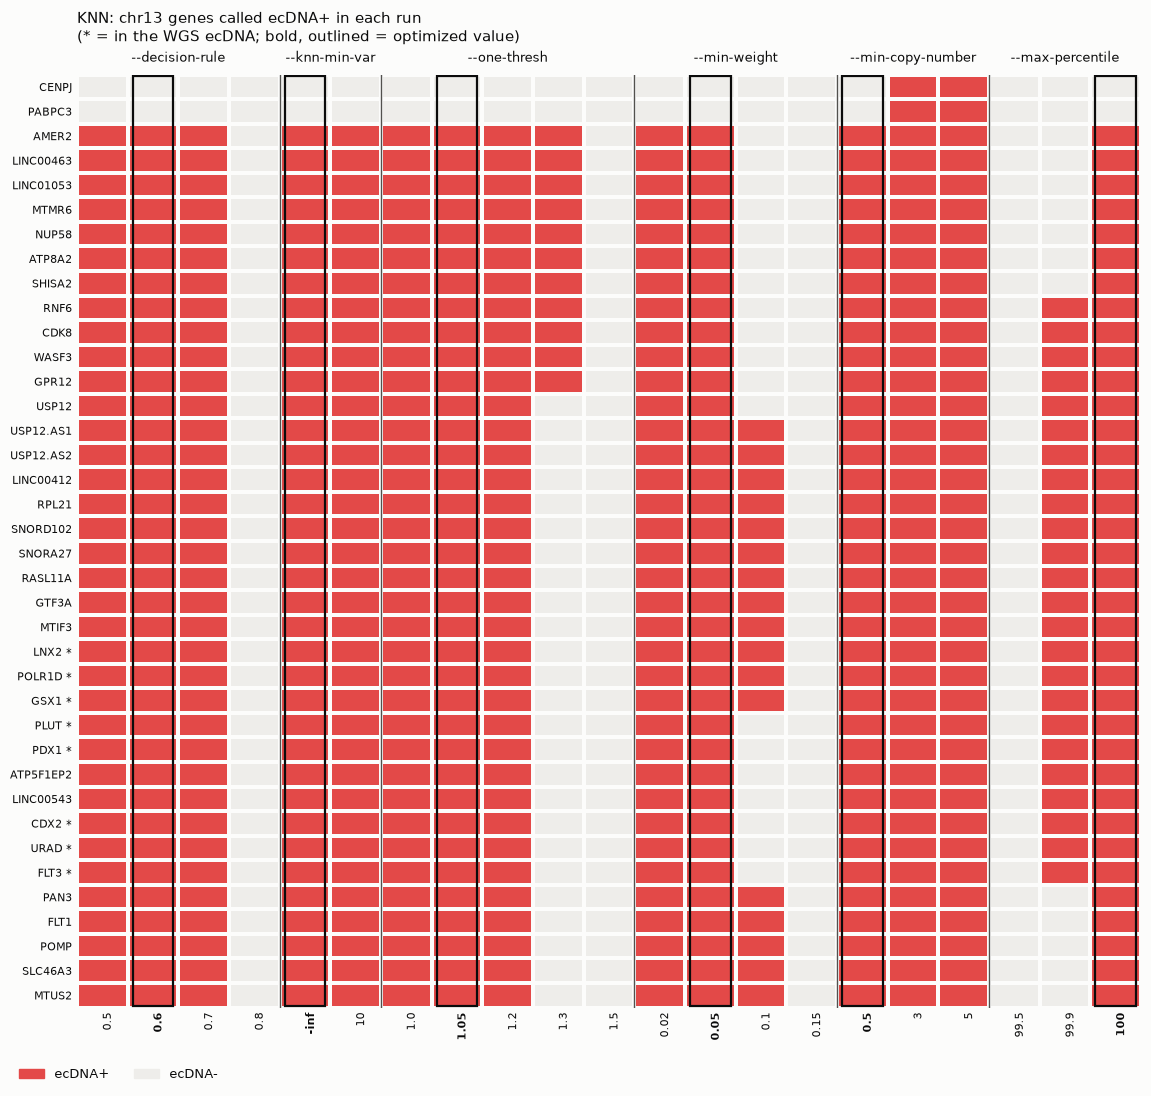

In [15]:
plot_sweep_genes(calls_knn, SWEEP_KNN, OPTIMIZED_KNN, "KNN: chr13 genes called ecDNA+ in each run", "knn_sweep_genes.png")


## 7. Your own data
Runs the same one-setting-at-a-time sweep on your own copy-number table, for the settings that changed the calls
most in sections 5 and 6. Set the four values in the next cell; by default they point at the example file.

**How to choose settings.** There is no ground truth, so look for values that
- call the genes you expect on ecDNA,
- keep regions you know are not ecDNA (for example a gained chromosome arm) ecDNA−,
- sit in the middle of a range of values that give the same calls, not at a tipping point.

Where the GMM and KNN disagree on a gene, look at it with `plot_gmm` and `plot_knn`.


In [ ]:
# ---- your data: edit these ----
MY_DATA = EXAMPLE              # copy-number table: one row per cell, one column per gene (as in the example)
MY_NAME = "mydata"             # name used in the titles and figure file names
MY_REFERENCE = set(WGS_ECDNA)  # genes you expect on ecDNA (e.g. from WGS), marked * in the charts; set() if none
MY_CHROMS = None               # e.g. ["chr8", "chr12"] to keep only these chromosomes (faster); None = all

my_cn = pd.read_csv(MY_DATA, sep="\t", index_col=0)
if MY_CHROMS:   # keep only these chromosomes
    my_cn = my_cn[[gene for gene in my_cn.columns if CHROM.get(gene) in MY_CHROMS]]
print(f"{MY_NAME}: {my_cn.shape[0]:,} cells x {my_cn.shape[1]:,} genes; "
      f"reference genes present: {len(MY_REFERENCE & set(my_cn.columns))} of {len(MY_REFERENCE)}")

MY_SWEEP_GMM = {"decision_rule": [0.4, 0.5, 0.6, 0.7], "one_thresh": [1.0, 1.05, 1.2],
                "min_weight": [0.02, 0.05, 0.1], "max_percentile": [99.5, 99.9, 100]}
MY_SWEEP_KNN = {"decision_rule": [0.5, 0.6, 0.7], "one_thresh": [1.05, 1.3],
                "min_weight": [0.02, 0.05, 0.1], "max_percentile": [99.9, 100]}


def tune(method, optimized, sweep):
    """Sweep on your data, then the summary table and the gene chart (all chromosomes)."""
    my_calls = run_sweep(optimized, sweep, counts_df=my_cn)
    sweep_table(my_calls, optimized, f"{MY_NAME}, {method.upper()}: one setting changed at a time", chroms=())
    plot_sweep_genes(my_calls, sweep, optimized, f"{MY_NAME}, {method.upper()}: genes called ecDNA+ in each run",
                     f"{MY_NAME}_{method}_sweep_genes.png", chrom=None, reference=MY_REFERENCE,
                     reference_label="reference gene")
    return my_calls


Each sweep below is 13 (GMM) or 10 (KNN) `pipelines.predict` runs, 5 at a time. On the example that is a few
minutes; a whole-genome table takes much longer, so use `MY_CHROMS` to start with the chromosomes you care about.


In [ ]:
my_gmm = tune("gmm", OPTIMIZED, MY_SWEEP_GMM)


In [ ]:
my_knn = tune("knn", OPTIMIZED_KNN, MY_SWEEP_KNN)
